# Smart Property Price Predictor — Model Evaluation
Weeks 9–10 Hack-O-Week

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    precision_score, recall_score, f1_score, roc_auc_score,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Load dataset

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Dataset shape:", df.shape)
print("\\nMissing values:\\n", df.isnull().sum())
df.describe().round(2)

Dataset shape: (20640, 9)
\nMissing values:\n MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


## 2. Feature engineering

In [4]:
df["PriceUSD"] = df["MedHouseVal"] * 100000
df["RoomsPerBedroom"] = df["AveRooms"] / df["AveBedrms"].replace(0, np.nan)
df["PeoplePerRoom"] = df["Population"] / df["AveRooms"].replace(0, np.nan)
df["LocationBand"] = pd.cut(df["Longitude"], bins=5, labels=False)

df = df.drop(columns=["MedHouseVal"])
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,PriceUSD,RoomsPerBedroom,PeoplePerRoom,LocationBand
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,452600.0,6.821705,46.104545,1
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,358500.0,6.418626,384.890548,1
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,352100.0,7.721053,59.844581,1
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,341300.0,5.421277,95.919937,1
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,342200.0,5.810714,89.941610,1


## 3. Simulate missing data and handle it

The original dataset is generally complete. To demonstrate missing-data handling, this section creates a copy with a small number of feature values masked as missing. The test target is not altered.

In [5]:
rng = np.random.default_rng(42)
df_missing = df.copy()
feature_cols = df_missing.drop(columns="PriceUSD").columns.tolist()

for col in feature_cols:
    mask = rng.random(len(df_missing)) < 0.02
    df_missing.loc[mask, col] = np.nan

print("Missing values before handling:")
display(df_missing.isnull().sum().to_frame("Missing count").query("`Missing count` > 0"))

Missing values before handling:


,Missing count
MedInc,415
HouseAge,421
AveRooms,397
AveBedrms,394
Population,433
AveOccup,409
Latitude,454
Longitude,407
RoomsPerBedroom,392
PeoplePerRoom,376


## 4. Prepare regression data

In [6]:
X = df_missing.drop(columns="PriceUSD")
y = df_missing["PriceUSD"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_features = X.columns.tolist()

regression_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

regression_model.fit(X_train, y_train)
reg_predictions = regression_model.predict(X_test)

regression_metrics = pd.DataFrame([{
    "MAE": mean_absolute_error(y_test, reg_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, reg_predictions)),
    "R2 Score": r2_score(y_test, reg_predictions)
}])

regression_metrics.round(2)

,MAE,RMSE,R2 Score
0,54304.96,74926.85,0.57


## 5. Cross-validation for regression

In [7]:
cv_scores = cross_validate(
    regression_model, X_train, y_train,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²"],
    "Mean CV score": [
        -cv_scores["test_mae"].mean(),
        -cv_scores["test_rmse"].mean(),
        cv_scores["test_r2"].mean()
    ],
    "Standard deviation": [
        cv_scores["test_mae"].std(),
        cv_scores["test_rmse"].std(),
        cv_scores["test_r2"].std()
    ]
}).round(3)

,Metric,Mean CV score,Standard deviation
0,MAE,53798.347,555.226
1,RMSE,73698.506,828.166
2,R²,0.593,0.007


## 6. Create price categories

In [8]:
price = df_missing["PriceUSD"]
y_class = pd.cut(
    price,
    bins=[-np.inf, 150000, 300000, np.inf],
    labels=["Affordable", "Mid-range", "Premium"]
)

print(y_class.value_counts(dropna=False))

PriceUSD
Mid-range     9184
Affordable    7620
Premium       3836
Name: count, dtype: int64


## 7. Classification train/test split

In [9]:
Xc = df_missing.drop(columns="PriceUSD")
valid = y_class.notna()
Xc = Xc.loc[valid]
yc = y_class.loc[valid]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

classification_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

classification_model.fit(X_train_c, y_train_c)
class_predictions = classification_model.predict(X_test_c)
class_probabilities = classification_model.predict_proba(X_test_c)

print(classification_report(y_test_c, class_predictions, zero_division=0))

              precision    recall  f1-score   support

  Affordable       0.80      0.73      0.76      1524
   Mid-range       0.66      0.79      0.72      1837
     Premium       0.77      0.54      0.64       767

    accuracy                           0.72      4128
   macro avg       0.74      0.69      0.71      4128
weighted avg       0.73      0.72      0.72      4128



## 8. Confusion matrix

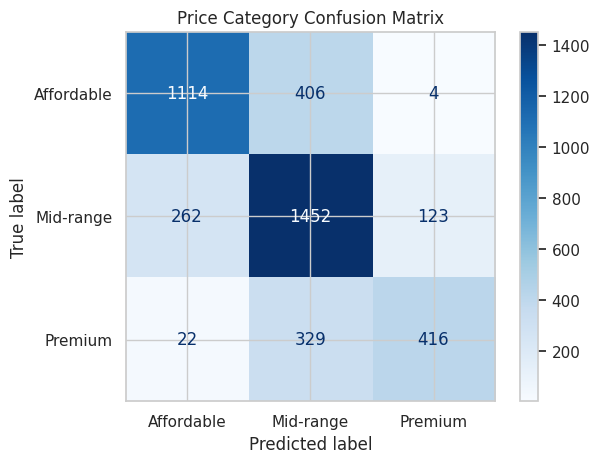

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test_c,
    class_predictions,
    labels=["Affordable", "Mid-range", "Premium"],
    cmap="Blues"
)
plt.title("Price Category Confusion Matrix")
plt.show()

## 9. Precision, recall, F1-score, and ROC-AUC

In [11]:
class_labels = ["Affordable", "Mid-range", "Premium"]
y_test_binary = label_binarize(y_test_c, classes=class_labels)

classification_metrics = pd.DataFrame([{
    "Accuracy": (class_predictions == y_test_c).mean(),
    "Precision (weighted)": precision_score(y_test_c, class_predictions, average="weighted", zero_division=0),
    "Recall (weighted)": recall_score(y_test_c, class_predictions, average="weighted", zero_division=0),
    "F1 (weighted)": f1_score(y_test_c, class_predictions, average="weighted", zero_division=0),
    "ROC-AUC (OvR weighted)": roc_auc_score(
        y_test_binary, class_probabilities, multi_class="ovr", average="weighted"
    )
}])

classification_metrics.round(3)

,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (OvR weighted)
0,0.722,0.732,0.722,0.721,0.854


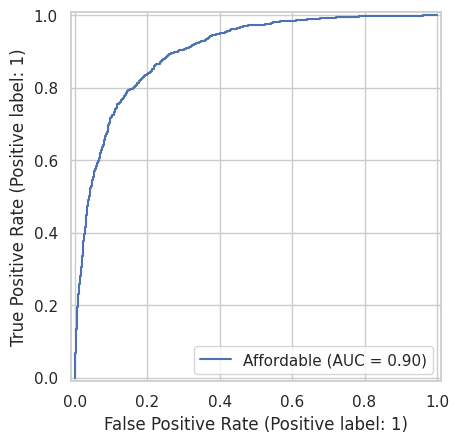

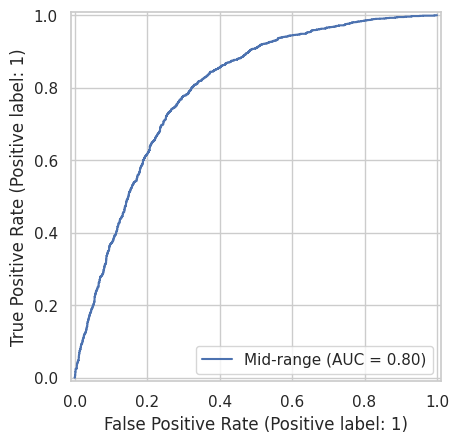

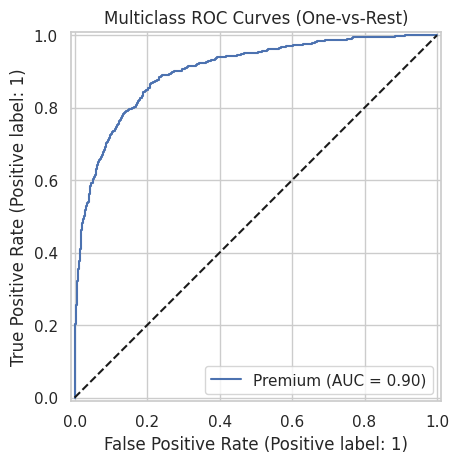

In [12]:
for i, label in enumerate(class_labels):
    RocCurveDisplay.from_predictions(
        y_test_binary[:, i],
        class_probabilities[:, i],
        name=label
    )
plt.plot([0, 1], [0, 1], "k--")
plt.title("Multiclass ROC Curves (One-vs-Rest)")
plt.show()

## 10. Feature scaling comparison

Compare Logistic Regression with and without standard scaling. Missing values are still imputed using training data within each pipeline.

In [13]:
unscaled_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LogisticRegression(max_iter=2000))
])

scaled_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

scaling_results = []

for name, model in [("Without scaling", unscaled_model), ("With scaling", scaled_model)]:
    model.fit(X_train_c, y_train_c)
    pred = model.predict(X_test_c)
    scaling_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_c, pred),
        "Precision": precision_score(y_test_c, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test_c, pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test_c, pred, average="weighted", zero_division=0)
    })

pd.DataFrame(scaling_results).round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


NameError: name 'accuracy_score' is not defined

## Conclusion
This notebook demonstrates train/test evaluation, five-fold cross-validation, confusion matrix, precision, recall, F1-score, multiclass ROC-AUC, feature engineering, feature scaling, and missing-value imputation. Regression is evaluated with MAE, RMSE, and R². The California Housing data describes area-level housing values, so predictions are educational estimates rather than current valuations for individual properties.